In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import requests

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)

API KEYS


In [3]:
api_key = ""

def api(key):
    global api_key
    api_key = key
    
def params_series(series_id):
    params = {
        'series_id': series_id,
        'api_key': api_key,
        'file_type': 'json'
    }
    return params

def get_series(series_id):
    url = 'https://api.stlouisfed.org/fred/series/observations'
    params = params_series(series_id)
    response = requests.get(url, params=params)
    data = response.json()
    df = pd.json_normalize(data["observations"])
    df["value"] = pd.to_numeric(df["value"], errors='coerce')
    df["date"] = pd.to_datetime(df["date"])
    return df

def params_search(search_text):
    params = {
        'search_text': search_text,
        'api_key': api_key,
        'file_type': 'json'
    }
    return params

def get_search(series_text):
    url = 'https://api.stlouisfed.org/fred/series/search'
    params = params_search(series_text)
    response = requests.get(url, params=params)
    data = response.json()
    df = pd.json_normalize(data["seriess"])
    return df

In [4]:
# API KEY

api("d099e8a4f1b849feb319c554d18cb172")

GDP INDONESIA


In [5]:
data = get_search("indonesia GDP")
data[["id", "title"]].head()

,id,title
0,NGDPRSAXDCIDQ,Real Gross Domestic Product for Indonesia
1,NGDPRNSAXDCIDQ,Real Gross Domestic Product for Indonesia
2,NGDPRXDCIDA,Real Gross Domestic Product for Indonesia
3,NGDPSAXDCIDQ,Nominal Gross Domestic Product for Indonesia
4,NGDPXDCIDA,Nominal Gross Domestic Product for Indonesia


In [6]:
data = get_series("NGDPRSAXDCIDQ")
data.tail()

,realtime_start,realtime_end,date,value
90,2024-08-05,2024-08-05,2022-07-01,2.928637e+09
91,2024-08-05,2024-08-05,2022-10-01,2.997079e+09
92,2024-08-05,2024-08-05,2023-01-01,3.022174e+09
93,2024-08-05,2024-08-05,2023-04-01,3.048359e+09
94,2024-08-05,2024-08-05,2023-07-01,3.073027e+09


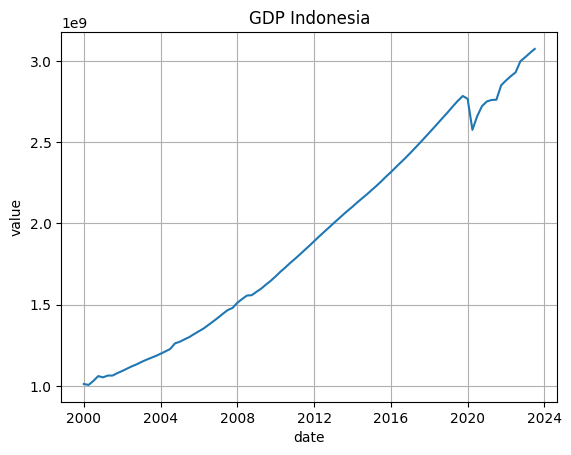

In [7]:
sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("GDP Indonesia")
plt.show()

In [8]:
# data = get_series("NGDPRSAXDCIDQ", "2020-08-10")
# data["year"] = data["date"].dt.year

# sns.lineplot(x="year", y="value", data=data, errorbar=None)
# plt.grid(True)
# plt.title("GDP Indonesia")

# years = data["year"].unique() 
# plt.xticks(ticks=years[::2], labels=years[::2])

# plt.tight_layout()
# plt.show()

SUKU BUNGA INDONESIA

In [9]:
data = get_search("indonesia interest rate")
data[["id", "title"]].head()

,id,title
0,INTDSRIDM193N,"Interest Rates, Discount Rate for Indonesia"
1,IR3TIB01IDM156N,Interest Rates: 3-Month or 90-Day Rates and Yields: Interbank Rates: Total for Indonesia
2,IR3TIB01IDA156N,Interest Rates: 3-Month or 90-Day Rates and Yields: Interbank Rates: Total for Indonesia
3,IR3TIB01IDQ156N,Interest Rates: 3-Month or 90-Day Rates and Yields: Interbank Rates: Total for Indonesia
4,IRSTCB01IDM156N,Interest Rates: Immediate Rates (< 24 Hours): Central Bank Rates: Total for Indonesia


In [10]:
data = get_series("IR3TIB01IDM156N")
data.head()

,realtime_start,realtime_end,date,value
0,2024-08-08,2024-08-08,1998-01-01,22.86
1,2024-08-08,2024-08-08,1998-02-01,24.00
2,2024-08-08,2024-08-08,1998-03-01,27.26
3,2024-08-08,2024-08-08,1998-04-01,29.40
4,2024-08-08,2024-08-08,1998-05-01,32.95


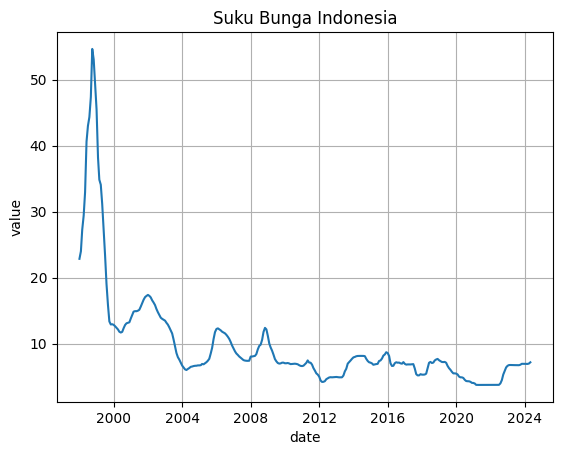

In [11]:
sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("Suku Bunga Indonesia")
plt.show()

INFLASI INDONESIA

In [12]:
data = get_search("indonesia inflation")
data[["id", "title"]].head()

,id,title
0,FPCPITOTLZGIDN,"Inflation, consumer prices for Indonesia"
1,CSINFT02IDM460S,Consumer Opinion Surveys: Consumer Prices: Future Tendency of Inflation: European Commission and National Indicators for Indonesia


In [13]:
data = get_series("FPCPITOTLZGIDN")
data.tail()

,realtime_start,realtime_end,date,value
59,2024-08-08,2024-08-08,2019-01-01,3.030587
60,2024-08-08,2024-08-08,2020-01-01,1.920968
61,2024-08-08,2024-08-08,2021-01-01,1.560130
62,2024-08-08,2024-08-08,2022-01-01,4.209464
63,2024-08-08,2024-08-08,2023-01-01,3.670131


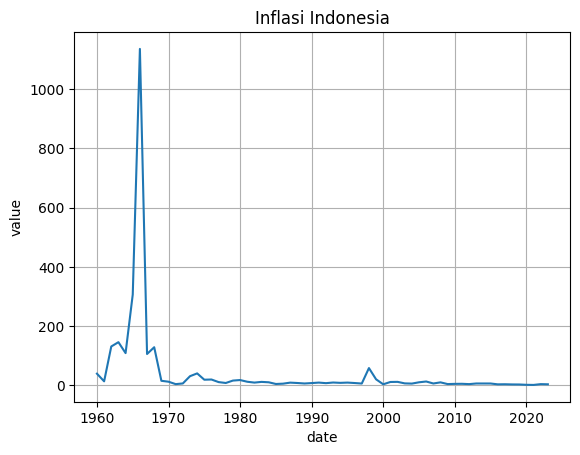

In [14]:
sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("Inflasi Indonesia")
plt.show()

NILAI TUKAR RUPIAH

In [15]:
data = get_search("indonesia exchange rate")
data[["id", "title"]].head()

,id,title
0,TWEXB,"Trade Weighted U.S. Dollar Index: Broad, Goods (DISCONTINUED)"
1,CCUSSP02IDM650N,"Currency Conversions: US Dollar Exchange Rate: Spot, End of Period: National Currency: USD for Indonesia"
2,CCUSSP02IDQ650N,"Currency Conversions: US Dollar Exchange Rate: Spot, End of Period: National Currency: USD for Indonesia"
3,CCUSSP02IDA650N,"Currency Conversions: US Dollar Exchange Rate: Spot, End of Period: National Currency: USD for Indonesia"
4,DTWEXB,Nominal Broad U.S. Dollar Index (Goods Only) (DISCONTINUED)


In [16]:
data = get_series("CCUSSP02IDM650N")
data.tail()

,realtime_start,realtime_end,date,value
679,2024-08-08,2024-08-08,2023-08-01,15239.0
680,2024-08-08,2024-08-08,2023-09-01,15526.0
681,2024-08-08,2024-08-08,2023-10-01,15916.0
682,2024-08-08,2024-08-08,2023-11-01,15384.0
683,2024-08-08,2024-08-08,2023-12-01,15416.0


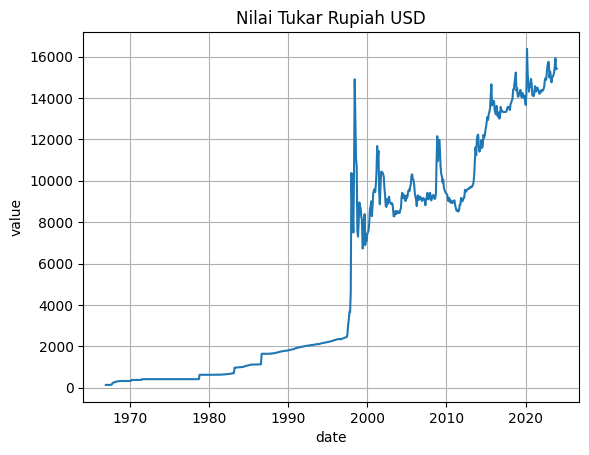

In [17]:
sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("Nilai Tukar Rupiah USD")
plt.show()

HARGA MINYAK

In [18]:
data = get_search("oil price")
data[["id", "title"]].head()

,id,title
0,DCOILWTICO,"Crude Oil Prices: West Texas Intermediate (WTI) - Cushing, Oklahoma"
1,MCOILWTICO,"Crude Oil Prices: West Texas Intermediate (WTI) - Cushing, Oklahoma"
2,WCOILWTICO,"Crude Oil Prices: West Texas Intermediate (WTI) - Cushing, Oklahoma"
3,ACOILWTICO,"Crude Oil Prices: West Texas Intermediate (WTI) - Cushing, Oklahoma"
4,DCOILBRENTEU,Crude Oil Prices: Brent - Europe


In [19]:
data = get_series("DCOILWTICO")
data.tail()

,realtime_start,realtime_end,date,value
10063,2024-08-08,2024-08-08,2024-07-30,76.17
10064,2024-08-08,2024-08-08,2024-07-31,79.36
10065,2024-08-08,2024-08-08,2024-08-01,77.74
10066,2024-08-08,2024-08-08,2024-08-02,74.99
10067,2024-08-08,2024-08-08,2024-08-05,74.46


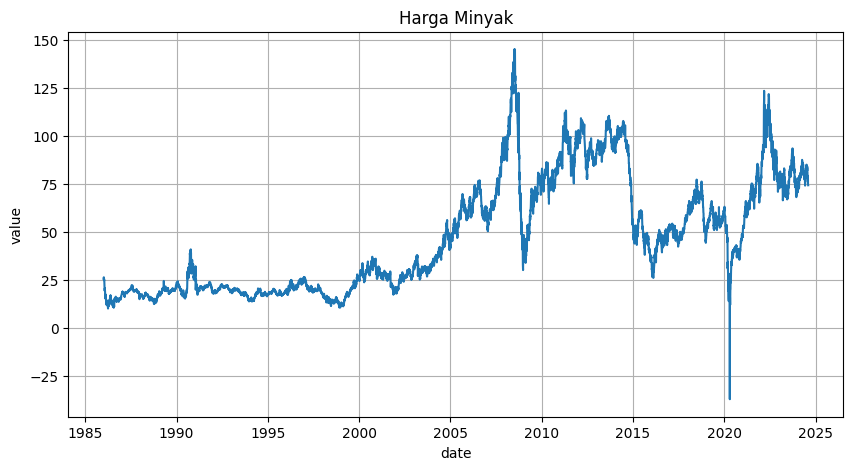

In [20]:
plt.figure(figsize=(10,5))
sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("Harga Minyak")
plt.show()

TINGKAT PENGANGGURAN

In [21]:
data = get_search("indonesia unemployment")
data[["id", "title"]].head()

,id,title
0,LRUNTTTTIDQ156N,Infra-Annual Labor Statistics: Unemployment Rate Total: 15 Years or over for Indonesia
1,LRUNTTTTIDA156N,Infra-Annual Labor Statistics: Unemployment Rate Total: 15 Years or over for Indonesia
2,SLUEM1524ZSIDN,Youth Unemployment Rate for Indonesia
3,LFUNTTTTIDQ647S,Infra-Annual Labor Statistics: Unemployment Total: 15 Years or over for Indonesia
4,LFUNTTTTIDA647S,Infra-Annual Labor Statistics: Unemployment Total: 15 Years or over for Indonesia


In [22]:
data = get_series("SLUEM1524ZSIDN")
data.tail()

,realtime_start,realtime_end,date,value
28,2024-08-08,2024-08-08,2019-01-01,13.592
29,2024-08-08,2024-08-08,2020-01-01,14.783
30,2024-08-08,2024-08-08,2021-01-01,13.810
31,2024-08-08,2024-08-08,2022-01-01,14.053
32,2024-08-08,2024-08-08,2023-01-01,13.936


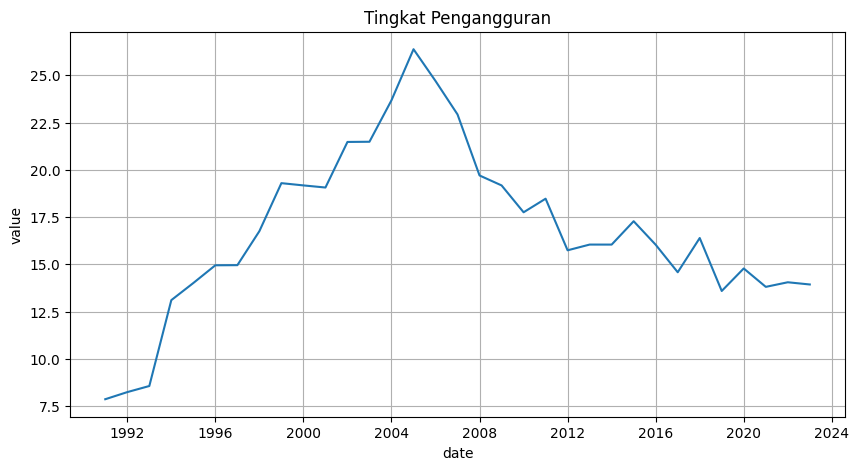

In [23]:
plt.figure(figsize=(10,5))
sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("Tingkat Pengangguran")
plt.show()